# 01 — Export fix-window data (Guiana)

Pipeline step 1: export training/test `.npy` files from one **fixed rotated window** on the full grid (not random crops). Set `CROP_HEIGHT` and `CROP_WIDTH` in the config cell (default 128×128). Uses `RotatedFixedCrop` from `src/data/useful_transforms.py`.

**Typical runs** (switch `DATA_PREFIX_BASE` + dates in the config cell)
- **Current:** 2023 Jan–Jun (first 6 months) → `data/sample_23_jan_jun_smallfixwin_uv_dt360_*` with `EXPORT_COMPONENTS = ("uv",)` (u+v, `iD=2`)
- 3 cond + 1 pred, **360 h (15-day) frame spacing** (`DT = 360`), **daily start anchor** (`HOUR_OF_DAY = 12`) → ~181 noon pool → `N_SAMPLES_TO_GEN = 181`
- `# Old holdout:` 2022 Jan–Apr → `data/sample_22_jan_apr_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 120`
- `# Old holdout:` 2017 Sep–Dec → `data/sample_17_sep_dec_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 122`
- `# Old holdout:` 2017 full year → `data/sample_17_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 365`
- `# Old train:` 2018–2021 → `data/sample_18_21_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 1461`
- `# Old holdout:` 2022 only → `data/sample_22_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 365`
- `# Old holdout:` 2023 only → `data/sample_23_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 319`
- `# Old holdout:` 2022–2023 → `data/sample_22_23_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 684`
- `# Old train:` 2013–2022 → `data/sample_13_22_smallfixwin_uv_dt360_*`, `N_SAMPLES_TO_GEN = 3600`
- `# Old:` 2016–2019 → `*_u_dt96_*` / `_v_dt96_*`, 4+56 frames, `DT = 96` | `DT = 24`

**Time step (`DT`)**
- `DT = 360` — **15-day / 360 h** between frames; 3 cond + 1 pred → 4 frames
- `# DT = 24` — 1-day frame spacing
- `# DT = 96` — 4-day steps, 60 frames (old)

**Window**
- **Small fix window (current):** 128×128 @ top=330, left=70, angle=-45°
- `# Large fix window:` 128×384 @ top=320, left=110 (commented in config cell)

**Channels / export mode (`EXPORT_COMPONENTS` in config)**
- **`("uv",)`** — u+v only → `*_uv_dt360_*`, shape `(N, 4, 2, H, W)`, training `iD=2`
- `# Old:` `("u", "v")` separate single-channel | u/v/ssh (`iD=3`)

**Time selection**
- **Which sequences**: random sample of valid start times in the date range
- **Daily anchor**: set `HOUR_OF_DAY = 12` (pool size depends on date range; ~181 for 2023 Jan–Jun)
  - `None` — random over all hours (0–23)
  - `[0, 12]` — midnight or noon starts

**Outputs per run**
- `{OUTPUT_PREFIX}_sims.npy` — `(N, 4, C, H, W)` with `C=2` for uv (3 cond + 1 pred)
- `{OUTPUT_PREFIX}_mask.npy` — `(N, H, W)` invalid mask (last conditioning frame)
- `{OUTPUT_PREFIX}_day.npy`, `_hour.npy`, `_latlon.npy`
- `{OUTPUT_PREFIX}_window.npy` — `[top, left, h, w, angle_deg]`
- `{OUTPUT_PREFIX}_export_config.json` — includes `channel_names`, `target_channel_indices`

In [1]:
import os
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from joblib import Parallel, delayed
from matplotlib.patches import Polygon

ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.dataloaders.guiana_margem_tensor import GuianaDataloader
from src.data.useful_transforms import RotatedFixedCrop, rotated_window_corners
from src.export.fix_window_export import candidate_indices_for_hour


In [2]:
ZARR_PATH = os.getenv(
    "GUIANA_ZARR_PATH",
    "s3://oceangen-data/margem_equatorial_tensor.zarr",
)

DT = 360  # 15-day / 360 h between frames
# DT = 24  # 1-day frame spacing
# DT = 96  # 4-day steps (old: 4 cond + 56 pred)
DT_STEP_DAYS = DT // 24
CONDITIONING_STEPS = 3
FORECAST_STEPS = 1
# CONDITIONING_STEPS = 4  # old
# FORECAST_STEPS = 56     # old

# --- window (small fix window, same location) ---
CROP_HEIGHT = 128
CROP_WIDTH = 128
WINDOW_TOP = 330
WINDOW_LEFT = 70
WINDOW_ANGLE = -45.0

# Large fix window (old):
# CROP_HEIGHT = 128
# CROP_WIDTH = 384
# WINDOW_TOP = 320
# WINDOW_LEFT = 110
# WINDOW_ANGLE = -45.0

# --- export components (channels + output prefix) ---
EXPORT_COMPONENTS = ("uv",)  # combined u+v only
# EXPORT_COMPONENTS = ("u", "v")  # separate single-channel exports (old)
# EXPORT_COMPONENTS = ("u",)     # u only (old)

# Match this to the active START_TIME / END_TIME block below
DATA_PREFIX_BASE = "data/sample_23_jan_jun_smallfixwin"
# DATA_PREFIX_BASE = "data/sample_22_jan_apr_smallfixwin"  # holdout 2022 Jan–Apr (old)
# DATA_PREFIX_BASE = "data/sample_17_sep_dec_smallfixwin"  # holdout 2017 Sep–Dec (old)
# DATA_PREFIX_BASE = "data/sample_17_smallfixwin"  # holdout 2017 full year (old)
# DATA_PREFIX_BASE = "data/sample_18_21_smallfixwin"  # train 2018–2021 (old)
# DATA_PREFIX_BASE = "data/sample_22_smallfixwin"  # holdout 2022 full year (old)
# DATA_PREFIX_BASE = "data/sample_23_smallfixwin"  # holdout 2023 full year (old)
# DATA_PREFIX_BASE = "data/sample_22_23_smallfixwin"  # holdout 2022–2023 (old)
# DATA_PREFIX_BASE = "data/sample_13_22_smallfixwin"  # train 2013–2022 (old)
# DATA_PREFIX_BASE = "data/sample_16_19_smallfixwin"  # old dt96 u/v
# DATA_PREFIX_BASE = "data/sample_10_19_fixwin"
# DATA_PREFIX_BASE = "data/sample_20_21_smallfixwin"



def _dt_suffix() -> str:
    if DT == 96:
        return "_dt96"
    if DT == 360:
        return "_dt360"
    return ""


def _component_export_settings(component: str):
    """Return (output_prefix, channel_names, target_channel_indices) for one export."""
    base = DATA_PREFIX_BASE
    tag = _dt_suffix()
    if component == "uv":
        return f"{base}_uv{tag}", ("u", "v"), (0, 1)
    if component == "u":
        return f"{base}_u{tag}", ("u",), (0,)
    if component == "v":
        return f"{base}_v{tag}", ("v",), (0,)
    raise ValueError(f"Unknown component {component!r}; use 'u', 'v', or 'uv'")

PREVIEW_COMPONENT = EXPORT_COMPONENTS[0]
OUTPUT_PREFIX, CHANNEL_NAMES, TARGET_CHANNEL_INDICES = _component_export_settings(PREVIEW_COMPONENT)

SEED = 42
N_JOBS = 30
MAX_MASK_FRAC = 0.4

# Daily start anchor (noon); pool size depends on START_TIME / END_TIME
HOUR_OF_DAY = 12

# --- choose period + output prefix ---

# Export (2023 Jan–Jun, first 6 months, DT=360, 3 cond + 1 pred, u+v):
START_TIME = "2023-01-01"
END_TIME = "2023-06-30"
N_SAMPLES_TO_GEN = 181  # all daily noon starts in pool (~181)

# Holdout export (2022 Jan–Apr, first 4 months, DT=360) — old:
# START_TIME = "2022-01-01"
# END_TIME = "2022-04-30"
# N_SAMPLES_TO_GEN = 120

# Holdout export (2017 Sep–Dec, last 4 months, DT=360) — old:
# START_TIME = "2017-09-01"
# END_TIME = "2017-12-31"
# N_SAMPLES_TO_GEN = 122

# Holdout export (2017 full year, DT=360) — old:
# START_TIME = "2017-01-01"
# END_TIME = "2017-12-31"
# N_SAMPLES_TO_GEN = 365

# Train export (2018–2021, DT=360, 3 cond + 1 pred, u+v) — old:
# START_TIME = "2018-01-01"
# END_TIME = "2021-12-31"
# N_SAMPLES_TO_GEN = 1461

# Rollout holdout export (2022 full year, DT=360, 3 cond + 1 pred, u+v) — old:
# START_TIME = "2022-01-01"
# END_TIME = "2022-12-31"
# N_SAMPLES_TO_GEN = 365

# Rollout holdout export (2023 full year, DT=360, 3 cond + 1 pred, u+v) — old:
# START_TIME = "2023-01-01"
# END_TIME = "2023-12-31"
# N_SAMPLES_TO_GEN = 319

# Rollout holdout (2022–2023, DT=360) — old:
# START_TIME = "2022-01-01"
# END_TIME = "2023-12-31"
# N_SAMPLES_TO_GEN = 684

# Train export (2013–2022, DT=360, 3 cond + 1 pred, u+v) — old:
# START_TIME = "2013-01-01"
# END_TIME = "2022-12-31"
# N_SAMPLES_TO_GEN = 3600

# Train export (2016–2019, DT=96, 4+56, separate u/v) — old:
# START_TIME = "2016-01-01"
# END_TIME = "2019-12-31"
# N_SAMPLES_TO_GEN = 5000

# Train export (2010–2019, DT=96) — old:
# START_TIME = "2010-01-01"
# END_TIME = "2019-12-31"
# N_SAMPLES_TO_GEN = 20000

# Test export (2020–2021, DT=96) — old:
# START_TIME = "2020-01-01"
# END_TIME = "2021-12-31"
# N_SAMPLES_TO_GEN = 2000

In [3]:
fixed_crop = RotatedFixedCrop(
    size=(CROP_HEIGHT, CROP_WIDTH),
    top=WINDOW_TOP,
    left=WINDOW_LEFT,
    angle_deg=WINDOW_ANGLE,
)

base_kwargs = dict(
    path=ZARR_PATH,
    dt=DT,
    conditioning_steps=CONDITIONING_STEPS,
    forecast_steps=FORECAST_STEPS,
    start_time=START_TIME,
    end_time=END_TIME,
)

print("Opening Zarr:", ZARR_PATH)
dataset_full = GuianaDataloader(**base_kwargs)
dataset = GuianaDataloader(**base_kwargs, transform=fixed_crop)

info = dataset_full.info()
candidate_idx = candidate_indices_for_hour(dataset, HOUR_OF_DAY)
print("Valid samples:", len(dataset))
print("After hour filter:", len(candidate_idx), "| HOUR_OF_DAY =", HOUR_OF_DAY)
print(f"N_SAMPLES_TO_GEN: {N_SAMPLES_TO_GEN} | period: {START_TIME} → {END_TIME}")
if N_SAMPLES_TO_GEN > len(candidate_idx):
    print(
        f"WARNING: N_SAMPLES_TO_GEN={N_SAMPLES_TO_GEN} > pool {len(candidate_idx)}; "
        "export will use all hour-filtered indices"
    )
print("Grid (H, W):", info["space"]["height"], info["space"]["width"])
print(f"Crop size: {CROP_HEIGHT} x {CROP_WIDTH}")
print("Window:", fixed_crop)
print("Export components:", EXPORT_COMPONENTS)
print("Channels:", CHANNEL_NAMES, "| target:", tuple(CHANNEL_NAMES[i] for i in TARGET_CHANNEL_INDICES))
print("Output prefix (preview):", OUTPUT_PREFIX)


Opening Zarr: s3://oceangen-data/margem_equatorial_tensor.zarr
Valid samples: 4344
After hour filter: 181 | HOUR_OF_DAY = 12
N_SAMPLES_TO_GEN: 181 | period: 2023-01-01 → 2023-06-30
Grid (H, W): 431 547
Crop size: 128 x 128
Window: RotatedFixedCrop(size=(128, 128), top=330, left=70, angle_deg=-45.0)
Export components: ('uv',)
Channels: ('u', 'v') | target: ('u', 'v')
Output prefix (preview): data/sample_23_jan_jun_smallfixwin_uv_dt360


In [4]:
from src.export.fix_window_export import load_sequence


def load_full_sequence(dataset, idx: int):
    return load_sequence(dataset, idx, channel_names=CHANNEL_NAMES)


## Preview fixed window on full domain


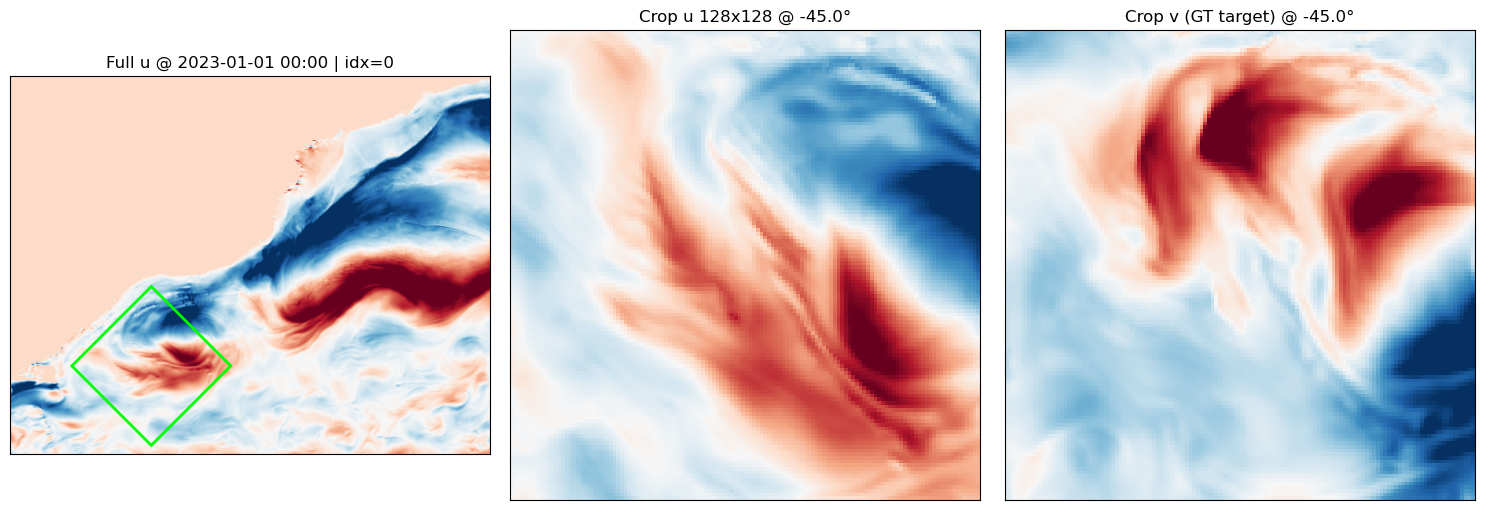

mask invalid fraction (crop): 0.0000
channels: ('u', 'v') | target: ['u', 'v']


In [5]:
PREVIEW_IDX = 0

seq_full, mask_full, times, _ = load_full_sequence(dataset_full, PREVIEW_IDX)
# Always load u+v for preview plot (independent of EXPORT_COMPONENTS)
seq_crop_uv, mask_crop, _, _ = load_sequence(dataset, PREVIEW_IDX, channel_names=("u", "v"))

H_FULL, W_FULL = seq_full.shape[-2], seq_full.shape[-1]
corners = rotated_window_corners(
    WINDOW_TOP, WINDOW_LEFT, CROP_HEIGHT, WINDOW_ANGLE, CROP_WIDTH
)
t0 = str(times[0])[:16]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
field_u = seq_full[0, 0]
field_v = seq_crop_uv[0, 1]
vmin_u, vmax_u = np.nanpercentile(field_u, 2), np.nanpercentile(field_u, 98)
vmin_v, vmax_v = np.nanpercentile(field_v, 2), np.nanpercentile(field_v, 98)

ax = axes[0]
ax.imshow(field_u, cmap="RdBu_r", vmin=vmin_u, vmax=vmax_u)
ax.add_patch(Polygon(corners, fill=False, edgecolor="lime", linewidth=2))
ax.set_title(f"Full u @ {t0} | idx={PREVIEW_IDX}")
ax.set_xticks([])
ax.set_yticks([])

ax = axes[1]
ax.imshow(seq_crop_uv[0, 0], cmap="RdBu_r", vmin=vmin_u, vmax=vmax_u)
ax.set_title(f"Crop u {CROP_HEIGHT}x{CROP_WIDTH} @ {WINDOW_ANGLE}°")
ax.set_xticks([])
ax.set_yticks([])

ax = axes[2]
ax.imshow(field_v, cmap="RdBu_r", vmin=vmin_v, vmax=vmax_v)
ax.set_title(f"Crop v (GT target) @ {WINDOW_ANGLE}°")
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

print(f"mask invalid fraction (crop): {float(mask_crop.mean()):.4f}")
print(f"channels: {CHANNEL_NAMES} | target: {[CHANNEL_NAMES[i] for i in TARGET_CHANNEL_INDICES]}")


## Parallel export (resumable)

The export runs in **chunks** on disk. If SSH disconnects or the machine reboots, re-run the last cell (or `./scripts/run_export_detached.sh`) — it resumes from the last completed chunk.

When `EXPORT_COMPONENTS = ("uv",)`, one combined u+v export runs. For the old `("u", "v")` mode, the export cell starts **one job per component** (separate state/chunk dirs and logs).

- Progress: `{OUTPUT_PREFIX}_export_state.json` (per component)
- Chunk cache: `{OUTPUT_PREFIX}_chunks/`
- Set `DETACHED = True` to start background jobs and return immediately (recommended for large `N_SAMPLES_TO_GEN`).


In [6]:
import json
import subprocess
from dataclasses import asdict

from src.export.fix_window_export import ExportConfig, run_export

# True  -> background job (survives notebook/SSH disconnect)
# False -> run in this kernel (still resumable if interrupted)
DETACHED = True
CHUNK_SIZE = 100  # samples per checkpoint on disk
RESUME = True


def _run_one_export(output_prefix: str, channel_names: tuple[str, ...], target_channel_indices: tuple[int, ...]):
    export_config = ExportConfig(
        zarr_path=ZARR_PATH,
        dt=DT,
        conditioning_steps=CONDITIONING_STEPS,
        forecast_steps=FORECAST_STEPS,
        crop_height=CROP_HEIGHT,
        crop_width=CROP_WIDTH,
        window_top=WINDOW_TOP,
        window_left=WINDOW_LEFT,
        window_angle=WINDOW_ANGLE,
        seed=SEED,
        n_jobs=N_JOBS,
        max_mask_frac=MAX_MASK_FRAC,
        hour_of_day=HOUR_OF_DAY,
        start_time=START_TIME,
        end_time=END_TIME,
        output_prefix=output_prefix,
        n_samples_to_gen=N_SAMPLES_TO_GEN,
        chunk_size=CHUNK_SIZE,
        channel_names=channel_names,
        target_channel_indices=target_channel_indices,
    )

    config_path = Path(f"{output_prefix}_export_config.json")
    config_path.write_text(json.dumps(asdict(export_config), indent=2, default=str))
    print(f"Wrote config: {config_path}")

    if DETACHED:
        log_dir = Path("logs")
        log_dir.mkdir(exist_ok=True)
        log_path = log_dir / f"export_{Path(output_prefix).name}.log"
        cmd = [
            sys.executable,
            "scripts/export_fix_window_data.py",
            "--output-prefix",
            output_prefix,
        ]
        if not RESUME:
            cmd.append("--no-resume")
        with open(log_path, "a") as log_file:
            proc = subprocess.Popen(
                cmd,
                stdout=log_file,
                stderr=subprocess.STDOUT,
                start_new_session=True,
                cwd=ROOT,
            )
        print(f"Started background export PID {proc.pid} -> {output_prefix}")
        print(f"Log: {log_path}")
        print(f"Monitor: tail -f {log_path}")
        print(
            f"Resume after reboot: python scripts/export_fix_window_data.py "
            f"--output-prefix {output_prefix}"
        )
    else:
        run_export(export_config, resume=RESUME)


for component in EXPORT_COMPONENTS:
    out_prefix, ch_names, tgt_idx = _component_export_settings(component)
    print(f"\n=== Export component: {component} -> {out_prefix} ===")
    _run_one_export(out_prefix, ch_names, tgt_idx)



=== Export component: uv -> data/sample_23_jan_jun_smallfixwin_uv_dt360 ===
Wrote config: data/sample_23_jan_jun_smallfixwin_uv_dt360_export_config.json
Started background export PID 3355519 -> data/sample_23_jan_jun_smallfixwin_uv_dt360
Log: logs/export_sample_23_jan_jun_smallfixwin_uv_dt360.log
Monitor: tail -f logs/export_sample_23_jan_jun_smallfixwin_uv_dt360.log
Resume after reboot: python scripts/export_fix_window_data.py --output-prefix data/sample_23_jan_jun_smallfixwin_uv_dt360
